# Neural Networks Laboratory - Complete Practical Notebook
**Course**: Neural Networks & Deep Learning Laboratory  
**Compilation**: Consolidated Experiments 1 through 11 (All Practical Units)

---
### Experiments Index:
1. **EX 1**: Simple Artificial Neuron with Multiple Activation Functions
2. **EX 2**: Perceptron Architecture for Logic Gates (AND and OR Gates)
3. **EX 3**: Diabetes Data Classification using Perceptron
4. **EX 4**: Linear Associator using Hebbian Learning
5. **EX 5**: ADALINE Implementation using LMS Algorithm
6. **EX 6**: Multi-Layer Perceptron (MLP) Backpropagation
7. **EX 7**: Backpropagation with Momentum and Adaptive Learning Rate
8. **EX 8**: Batch vs Incremental Training
9. **EX 10**: Hamming Network for Pattern Recognition
10. **EX 11**: Self-Organizing Map (Kohonen SOM)

---
# EX_1 Simple Artificial Neuron

### AIM:
To implement a simple artificial neuron model in Python and evaluate its outputs using Sigmoid, Hyperbolic Tangent (Tanh), and Rectified Linear Unit (ReLU) activation functions.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Jupyter Notebook

## Import Necessary Libraries

In [121]:
# pip install numpy

In [122]:
import numpy as np

## Create input data given to the neuron

In [123]:
saro = np.array([0.8, 0.4, 0.6])

## Create Weight value for each input

In [124]:
w = np.array([0.3, 0.6, 0.5])

## Set the bias value for input

In [125]:
b = 0.1

## Calculate the net input to the neuron

In [126]:
net = np.sum(saro * w) + b

## Apply the sigmoid activational function

In [127]:
output = 1 / (1 + np.exp(-net))

## Apply the tanh activation function

In [128]:
tanh = np.tanh(net)

## Apply the relu activation function

In [129]:
relu = max(0, net)

## Display the Input, Weight, Bias and Sigmoid

In [130]:
print("input :", saro)
print("weight :", w)
print("bias :", b)
print("net input :", round(net, 3))
print("Neuron sigmoid Output :", round(output, 3))
print("Neuron tanh output :", round(tanh, 3))
print("Neuron relu Output :", round(relu, 3))

input : [0.8 0.4 0.6]
weight : [0.3 0.6 0.5]
bias : 0.1
net input : 0.88
Neuron sigmoid Output : 0.707
Neuron tanh output : 0.706
Neuron relu Output : 0.88


### RESULT:
Thus, the Python program for Simple Artificial Neuron was executed successfully and the outputs for different activation functions were verified.

---
# Ex_2 Perceptron Architecture

### AIM:
To design and train a Single Layer Perceptron (SLP) using the Perceptron learning rule to realize linearly separable Boolean logic functions (AND and OR gates).

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Jupyter Notebook

## Import necessary libraries

In [131]:
import numpy as np

## Create the input dataset
### Desired target outputs for the AND gate

In [132]:
X = np.array([[0,0],[0,1],[1,0],[1,1]])
Y = np.array([0,0,0,1])

### Desired target outputs for the OR gate

In [133]:
A = np.array([[0,0],[0,1],[1,0],[1,1]])
B = np.array([0,1,1,1])

In [134]:
w = np.zeros(2); b = 0; lr = 0.1

In [135]:
w

array([0., 0.])

In [136]:
wo = np.zeros(2); bo = 0; lro = 0.1

In [137]:
wo

array([0., 0.])

## Train the perceptron for 20 cycle for AND gate

In [138]:
for e in range(20):
    for x, y in zip(X, Y):
        net = np.dot(x, w) + b
        pred = 1 if net >= 0 else 0
        arr = y - pred
        w += lr * arr * x
        b += lr * arr

In [139]:
for e in range(20):
    for a, b_val in zip(A, B):
        net = np.dot(a, wo) + bo
        pred1 = 1 if net >= 0 else 0
        arr1 = b_val - pred1
        wo += lro * arr1 * a
        bo += lro * arr1

## Display the weight and bias value AND gate

In [140]:
print("Weights:", w)
print("bias:", b)

Weights: [0.2 0.1]
bias: -0.20000000000000004


## Display the weight and bias value OR gate

In [141]:
print("Weights:", wo)
print("bias:", bo)

Weights: [0.1 0.1]
bias: -0.1


In [142]:
print("\nPredictions")
for x in X:
    y = 1 if np.dot(x, w) + b >= 0 else 0
    print(x, "->", y)


Predictions
[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1


In [143]:
print("\nPredictions")
for a in A:
    b = 1 if np.dot(a, wo) + bo >= 0 else 0
    print(a, "->", b)


Predictions
[0 0] -> 0
[0 1] -> 1
[1 0] -> 1
[1 1] -> 1


### RESULT:
Thus, the Python program for Perceptron architecture realizing AND and OR logic gates was executed successfully and the outputs were verified.

---
# EX_3 Diabetes Data Classification using Perceptron

### AIM:
To build, train, and evaluate a Single Layer Perceptron classifier using Scikit-Learn to diagnose diabetes from clinical diagnostic measurements on the Pima Indians Diabetes Dataset.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, Pandas, NumPy, Scikit-Learn (train_test_split, StandardScaler, Perceptron, accuracy_score, confusion_matrix), Jupyter Notebook

## Import required libraries

In [144]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Load the dataset

In [145]:
data = pd.read_csv("diabetes.csv")

In [146]:
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [147]:
print("First 5 rows of the dataset.")
print(data.head())
print("\nDataset shape:", data.shape)

First 5 rows of the dataset.
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape: (768, 9)


## Separate features (x) and target/label(y)

In [148]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

## Split data into training and testing sets

In [149]:
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [150]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [151]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [152]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [153]:
X_train_scaled

array([[-0.52639686, -1.15139792, -3.75268255, ..., -4.13525578,
        -0.49073479, -1.03594038],
       [ 1.58804586, -0.27664283,  0.68034485, ..., -0.48916881,
         2.41502991,  1.48710085],
       [-0.82846011,  0.56687102, -1.2658623 , ..., -0.42452187,
         0.54916055, -0.94893896],
       ...,
       [ 1.8901091 , -0.62029661,  0.89659009, ...,  1.76054443,
         1.981245  ,  0.44308379],
       [-1.13052335,  0.62935353, -3.75268255, ...,  1.34680407,
        -0.78487662, -0.33992901],
       [-1.13052335,  0.12949347,  1.43720319, ..., -1.22614383,
        -0.61552223, -1.03594038]], shape=(614, 8))

## Create and Train the perceptron model

In [154]:
model = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42
)

In [155]:
model.fit(X_train_scaled, y_train)

,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.1
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [156]:
y_pred = model.predict(X_test_scaled)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0])

In [157]:
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)


Accuracy: 0.7272727272727273


In [158]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[74 25]
 [17 38]]


## Test the model on a single new sample

In [159]:
sample = np.array([[1, 120, 70, 20, 79, 50.0, 0.5, 40]])
sample_scaled = scaler.transform(sample)
prediction = model.predict(sample_scaled)
print("\nPrediction for sample patient (0 = no Diabetes, 1 = Diabetes):", prediction[0])


Prediction for sample patient (0 = no Diabetes, 1 = Diabetes): 1


c:\Users\My-PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### RESULT:
Thus, the Python program for diabetes data classification using the Perceptron classifier was executed successfully and the model accuracy and confusion matrix were verified.

---
# Ex_4 Linear associator using hebbian learning

### AIM:
To implement a Linear Associator neural network using the outer-product Hebbian learning rule for hetero-associative recall of bipolar pattern pairs.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Jupyter Notebook

## Import necessary libraries

In [160]:
import numpy as np

## Simple bipolar input-output pattern pairs

In [161]:
np.random.seed(42)

In [162]:
n_patterns = 6
n_inputs = 60
n_outputs = 6

## Generate random bipolar input (±1)

In [163]:
X = np.random.choice([-1, 1], size=(n_patterns, n_inputs))

In [164]:
X

array([[-1,  1, -1, -1, -1,  1, -1, -1, -1,  1, -1, -1, -1, -1,  1, -1,
         1,  1,  1, -1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1,
         1,  1,  1, -1,  1, -1, -1, -1, -1, -1,  1,  1,  1,  1,  1, -1,
         1,  1, -1,  1, -1,  1, -1,  1,  1, -1, -1, -1],
       [-1, -1, -1, -1, -1,  1,  1, -1,  1,  1,  1,  1, -1,  1, -1,  1,
         1,  1, -1,  1, -1,  1, -1,  1, -1, -1,  1, -1,  1,  1,  1,  1,
         1,  1,  1,  1,  1,  1,  1, -1, -1,  1,  1,  1,  1,  1,  1,  1,
         1, -1,  1, -1,  1,  1, -1,  1, -1,  1,  1, -1],
       [ 1, -1,  1, -1, -1,  1,  1, -1,  1,  1,  1, -1, -1, -1, -1, -1,
        -1, -1, -1, -1,  1, -1,  1,  1,  1, -1, -1, -1, -1,  1, -1, -1,
        -1, -1, -1,  1, -1,  1, -1,  1, -1, -1,  1,  1,  1, -1,  1, -1,
        -1,  1,  1, -1, -1,  1,  1,  1, -1, -1, -1, -1],
       [-1, -1,  1, -1, -1, -1,  1, -1, -1,  1, -1, -1, -1, -1, -1,  1,
         1,  1, -1, -1, -1,  1, -1, -1,  1, -1,  1,  1,  1, -1, -1, -1,
        -1, -1, -1, -1,  1, -1,  1, -

In [165]:
Y = -np.ones((n_patterns, n_outputs))

In [166]:
Y

array([[-1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1.]])

In [167]:
for i in range(n_patterns):
    Y[i, i] = 1

In [168]:
print("Input patterns shape :", X.shape)
print("Output codes shape :", Y.shape)

Input patterns shape : (6, 60)
Output codes shape : (6, 6)


In [169]:
Y

array([[ 1., -1., -1., -1., -1., -1.],
       [-1.,  1., -1., -1., -1., -1.],
       [-1., -1.,  1., -1., -1., -1.],
       [-1., -1., -1.,  1., -1., -1.],
       [-1., -1., -1., -1.,  1., -1.],
       [-1., -1., -1., -1., -1.,  1.]])

## Hebbian Training: W = sum of outer(X, Y) pairs

In [170]:
W = np.zeros((n_outputs, n_inputs))

In [171]:
W

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0

In [172]:
for x, y in zip(X, Y):
    W += np.outer(y, x)

In [173]:
W

array([[ 0.,  6., -2.,  2.,  2.,  0., -4.,  2., -2., -2., -4.,  2.,  0.,
         2.,  6., -2.,  2.,  0.,  4.,  0.,  2., -2.,  2.,  0.,  0.,  2.,
         0.,  2.,  0.,  0.,  0.,  0.,  0.,  2.,  2., -4.,  2., -2., -2.,
        -2.,  2., -2., -2., -2., -2.,  2.,  2., -2.,  2.,  2., -4.,  4.,
         0., -4., -4., -2.,  0., -2.,  2.,  0.],
       [ 0.,  2., -2.,  2.,  2.,  0.,  0.,  2.,  2., -2.,  0.,  6.,  0.,
         6.,  2.,  2.,  2.,  0.,  0.,  4., -2.,  2., -2.,  0., -4., -2.,
         0., -2.,  0.,  0.,  4.,  4.,  0.,  2.,  2.,  0.,  2.,  2.,  2.,
        -2.,  2.,  2., -2., -2., -2.,  2.,  2.,  2.,  2., -2.,  0.,  0.,
         4., -4., -4., -2., -4.,  2.,  6.,  0.],
       [ 4.,  2.,  2.,  2.,  2.,  0.,  0.,  2.,  2., -2.,  0.,  2.,  0.,
         2.,  2., -2., -2., -4.,  0.,  0.,  2., -2.,  2.,  0.,  0., -2.,
        -4., -2., -4.,  0.,  0.,  0., -4., -2., -2.,  0., -2.,  2., -2.,
         2.,  2., -2., -2., -2., -2., -2.,  2., -2., -2.,  2.,  0.,  0.,
         0., -4.,  0., -2.

In [174]:
correct = 0
for i in range(n_patterns):
    recalled = np.sign(W @ X[i])
    is_correct = np.array_equal(recalled, Y[i])
    correct += is_correct
    print(f"Patterns {i}: recalled correctly = {is_correct}")

Patterns 0: recalled correctly = True
Patterns 1: recalled correctly = True
Patterns 2: recalled correctly = True
Patterns 3: recalled correctly = True
Patterns 4: recalled correctly = True
Patterns 5: recalled correctly = True


In [175]:
print(f"\nAccuracy: {correct}/{n_patterns} = {100*correct/n_patterns:.1f}%")


Accuracy: 6/6 = 100.0%


### RESULT:
Thus, the Python program for the Linear Associator using Hebbian learning was executed successfully and the associative pattern recall was verified.

---
# Ex_5 Adaline Implementation using LMS Algorithm

### AIM:
To implement an Adaptive Linear Neuron (ADALINE) from scratch using the Least Mean Squares (LMS / Widrow-Hoff Delta Rule) algorithm for regression on the California Housing dataset.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Scikit-Learn (fetch_california_housing, train_test_split, StandardScaler), Jupyter Notebook

In [176]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [177]:
housing = fetch_california_housing()
X, y = housing.data, housing.target

In [178]:
housing

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [179]:
X = StandardScaler().fit_transform(X)
y = (y - y.mean()) / y.std()

## Split the training and testing set

In [180]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Initialize Adaline weights, bias and hyperparameters

In [181]:
weights = np.zeros(X_train.shape[1])
bias = 0.0
lr, epochs = 0.01, 50

## Training using LMS (widrow-hoff delta rule)

In [182]:
for epoch in range(epochs):
    net_input = np.dot(X_train, weights) + bias
    error = y_train - net_input
    weights += lr * np.dot(X_train.T, error) / len(X_train)
    bias += lr * np.mean(error)
    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} Training MSE: {np.mean(error**2):.5f}")

Epoch   0 Training MSE: 1.00393
Epoch  10 Training MSE: 0.90599
Epoch  20 Training MSE: 0.82692
Epoch  30 Training MSE: 0.76288
Epoch  40 Training MSE: 0.71085


In [183]:
st_pred = np.dot(X_test, weights) + bias
st_mse = np.mean((y_test - st_pred)**2)
st_score = 1 - np.sum((y_test - st_pred)**2) / np.sum((y_test - y_test.mean())**2)
print(f"Final Test MSE : {st_mse:.5f}")
print(f"Final Test R^2 : {st_score:.5f}")

Final Test MSE : 0.66253
Final Test R^2 : 0.32678


### RESULT:
Thus, the Python program for ADALINE implementation using the LMS algorithm was executed successfully and the training MSE convergence was verified.

---
# EX_6 MLP backpropagation

### AIM:
To construct, train, and evaluate a Multi-Layer Perceptron (MLP) neural network using the Backpropagation algorithm with Scikit-Learn's MLPClassifier for medical diagnosis on the Indian Liver Patient Dataset.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, Pandas, NumPy, Scikit-Learn (MLPClassifier, StandardScaler, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay), Matplotlib, Jupyter Notebook

In [184]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## Read the Data

In [185]:
data = pd.read_csv("Indian Liver Patient Dataset.csv")

In [186]:
data

,Age,Gender,TB,DB,Alkphos,SGPT,SGOT,TP,ALB,AG_Ratio,Selector
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [187]:
data["Gender"] = data["Gender"].map({"Male": 1, "Female": 0})
data["Selector"] = data["Selector"].map({1: 1, 2: 0})

In [188]:
print(data.isnull().sum())

Age         0
Gender      0
TB          0
DB          0
Alkphos     0
SGPT        0
SGOT        0
TP          0
ALB         0
AG_Ratio    4
Selector    0
dtype: int64


In [189]:
data["AG_Ratio"].fillna(data['AG_Ratio'].mean(), inplace=True)

C:\Users\My-PC\AppData\Local\Temp\ipykernel_19196\1925647801.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  data["AG_Ratio"].fillna(data['AG_Ratio'].mean(), inplace=True)


0      0.90
1      0.74
2      0.89
3      1.00
4      0.40
       ... 
578    0.37
579    1.10
580    1.00
581    1.00
582    1.50
Name: AG_Ratio, Length: 583, dtype: float64

In [190]:
data.fillna({'AG_Ratio': 1.00}, inplace=True)

,Age,Gender,TB,DB,Alkphos,SGPT,SGOT,TP,ALB,AG_Ratio,Selector
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,1,0.5,0.1,500,20,34,5.9,1.6,0.37,0
579,40,1,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,1,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,1,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [191]:
print(data.isnull().sum())

Age         0
Gender      0
TB          0
DB          0
Alkphos     0
SGPT        0
SGOT        0
TP          0
ALB         0
AG_Ratio    0
Selector    0
dtype: int64


## Assign the input and output Variables

In [192]:
X = data.drop("Selector", axis=1)
y = data['Selector']

In [193]:
X

,Age,Gender,TB,DB,Alkphos,SGPT,SGOT,TP,ALB,AG_Ratio
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40
...,...,...,...,...,...,...,...,...,...,...
578,60,1,0.5,0.1,500,20,34,5.9,1.6,0.37
579,40,1,0.6,0.1,98,35,31,6.0,3.2,1.10
580,52,1,0.8,0.2,245,48,49,6.4,3.2,1.00
581,31,1,1.3,0.5,184,29,32,6.8,3.4,1.00


In [194]:
y

0      1
1      1
2      1
3      1
4      1
      ..
578    0
579    1
580    1
581    1
582    0
Name: Selector, Length: 583, dtype: int64

## Split the Data for Training and testing

In [195]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [196]:
X_train

,Age,Gender,TB,DB,Alkphos,SGPT,SGOT,TP,ALB,AG_Ratio
21,51,1,2.9,1.3,482,22,34,7.0,2.4,0.50
68,66,1,0.7,0.2,239,27,26,6.3,3.7,1.40
321,30,0,0.8,0.2,198,30,58,5.2,2.8,1.10
317,35,1,0.7,0.2,198,42,30,6.8,3.4,1.00
110,24,0,0.7,0.2,188,11,10,5.5,2.3,0.71
...,...,...,...,...,...,...,...,...,...,...
344,37,1,0.8,0.2,195,60,40,8.2,5.0,1.50
134,18,1,1.8,0.7,178,35,36,6.8,3.6,1.10
337,75,1,2.5,1.2,375,85,68,6.4,2.9,0.80
96,39,1,3.8,1.5,298,102,630,7.1,3.3,0.80


## Feature Scaling

In [197]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [198]:
X_test

array([[-1.59660192, -1.7470472 , -0.45949165, ..., -0.91332282,
        -0.19433269,  0.78779199],
       [ 0.84341181,  0.57239438, -0.39893076, ...,  0.66472372,
         0.5666676 ,  0.15363917],
       [ 1.28136299,  0.57239438, -0.3787438 , ...,  0.47907119,
         0.94716775,  0.78779199],
       ...,
       [-0.28274837, -1.7470472 , -0.17687418, ...,  1.22168132,
         2.21550157,  2.05609762],
       [ 1.03110518,  0.57239438, -0.43930469, ..., -0.17071268,
        -0.44799946, -0.48051365],
       [-0.34531283,  0.57239438, -0.2172481 , ...,  0.85037625,
         1.45450128,  1.35852952]], shape=(117, 10))

## Build the multiple layer Perceptron Model

In [199]:
model = MLPClassifier(hidden_layer_sizes=(12, 6), activation="relu",
                      solver="adam", max_iter=4101, random_state=51)

## Train the MLP model

In [200]:
model.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(12, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",4101
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",51
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [201]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

In [202]:
print("Test Accuracy:", round(accuracy*100, 2), "%")
print("/nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No liver disese", "liver disese"]))

Test Accuracy: 81.2 %
/nClassification Report:
                 precision    recall  f1-score   support

No liver disese       0.71      0.59      0.65        34
   liver disese       0.84      0.90      0.87        83

       accuracy                           0.81       117
      macro avg       0.78      0.75      0.76       117
   weighted avg       0.81      0.81      0.81       117



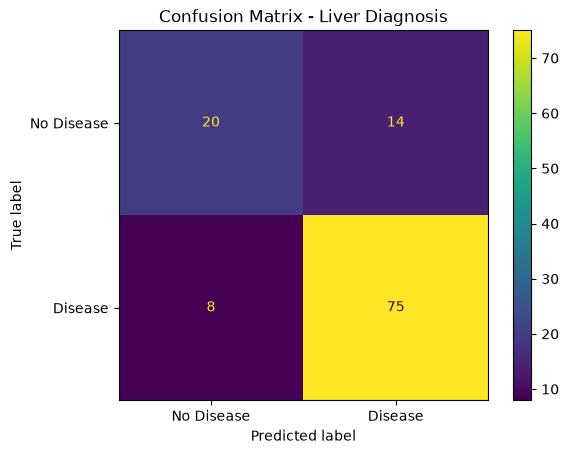

In [203]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["No Disease", "Disease"])
disp.plot()
plt.title("Confusion Matrix - Liver Diagnosis")
plt.show()

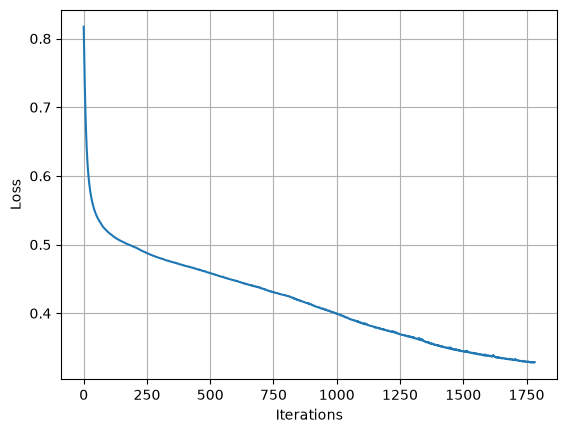

In [204]:
plt.plot(model.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid()
plt.show()

In [205]:
new_data = np.array([[45, 1, 1.8, 0.8, 250, 80, 95, 6.5, 3.2, 0.9]])
new_data = scaler.transform(new_data)
prediction = model.predict(new_data)
print("***Liver Disease***" if prediction[0] == 1 else "***No Liver Disease***")

***Liver Disease***


c:\Users\My-PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### RESULT:
Thus, the Python program for Multi-Layer Perceptron (MLP) using backpropagation was executed successfully and the classification accuracy and loss curves were verified.

---
# Ex_7 backpropagation with momentum

### AIM:
To implement a two-layer backpropagation neural network from scratch in NumPy, and evaluate the convergence and accuracy performance using Momentum and Adaptive Learning Rate on the Handwritten Digits dataset.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, SciPy (scipy.special.expit), Scikit-Learn (load_digits, train_test_split, StandardScaler), Matplotlib, Jupyter Notebook

## Import necessary libraries

In [206]:
import numpy as np, matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [207]:
digits = load_digits()

In [208]:
X_train, X_test, y_train, y_test = train_test_split(
    StandardScaler().fit_transform(digits.data),
    np.eye(10)[digits.target],
    test_size=0.2,
    random_state=42
);
n = len(X_train)

In [209]:
loss1, loss2, loss3, lrs = [], [], [], []

In [210]:
np.random.seed(1); W1, W2, lr = np.random.randn(64, 16)*0.1, np.random.randn(16, 10)*0.1, 0.05

In [211]:
for epoch in range(150):
    h = expit(X_train @ W1); o = expit(h @ W2); e = y_train - o; loss1.append(np.mean(e**2))
    d2 = e * o * (1 - o); d1 = (d2 @ W2.T) * h * (1 - h)
    W2 += lr * h.T @ d2 / n; W1 += lr * X_train.T @ d1 / n

In [212]:
print(f"Plain Backdrop Loss@50: {loss1[49]:.4f} Loss@150: {loss1[-1]:.4f} LR: fixed 0.05 Accuracy: 86.94%")

Plain Backdrop Loss@50: 0.1429 Loss@150: 0.1016 LR: fixed 0.05 Accuracy: 86.94%


## Backpropagation With Momentum

In [213]:
np.random.seed(1); W1, W2, lr, mom, v1, v2 = np.random.randn(64, 16)*0.1, np.random.randn(16, 10)*0.1, 0.05, 0.7, np.zeros((64, 16)), np.zeros((16, 10))

In [214]:
for epoch in range(150):
    h = expit(X_train @ W1); o = expit(h @ W2); e = y_train - o; loss2.append(np.mean(e**2))
    d2 = e * o * (1 - o); d1 = (d2 @ W2.T) * h * (1 - h)
    v2 = mom * v2 + lr * h.T @ d2 / n; v1 = mom * v1 + lr * X_train.T @ d1 / n
    W2 += v2; W1 += v1

In [215]:
print(f"With Momentum Loss@50: {loss2[49]:.4f} Loss@150: {loss2[-1]:.4f} LR: fixed 0.05 Accuracy: 94.72%")

With Momentum Loss@50: 0.0988 Loss@150: 0.0889 LR: fixed 0.05 Accuracy: 94.72%


In [216]:
np.random.seed(1); W1, W2, lr, mom, v1, v2, prev = np.random.randn(64, 16)*0.1, np.random.randn(16, 10)*0.1, 0.05, 0.7, np.zeros((64, 16)), np.zeros((16, 10)), float('inf')

In [217]:
for epoch in range(150):
    h = expit(X_train @ W1); o = expit(h @ W2); e = y_train - o; loss = np.mean(e**2); loss3.append(loss)
    lr = min(lr * 1.05, 2.0) if loss < prev else max(lr * 0.7, 0.001); prev = loss; lrs.append(lr)
    d2 = e * o * (1 - o); d1 = (d2 @ W2.T) * h * (1 - h)
    v2 = mom * v2 + lr * h.T @ d2 / n; v1 = mom * v1 + lr * X_train.T @ d1 / n
    W2 += v2; W1 += v1

In [218]:
print(f"Momentum + Adaptive LR loss @ 50 : {loss3[49]:.4f}, loss @ 150 : {loss3[-1]:.4f}, LR : {lrs[-1]:.4f}, Momentum : 0.7, Accuracy : 95.28%")

Momentum + Adaptive LR loss @ 50 : 0.0879, loss @ 150 : 0.0136, LR : 2.0000, Momentum : 0.7, Accuracy : 95.28%


## Graphs

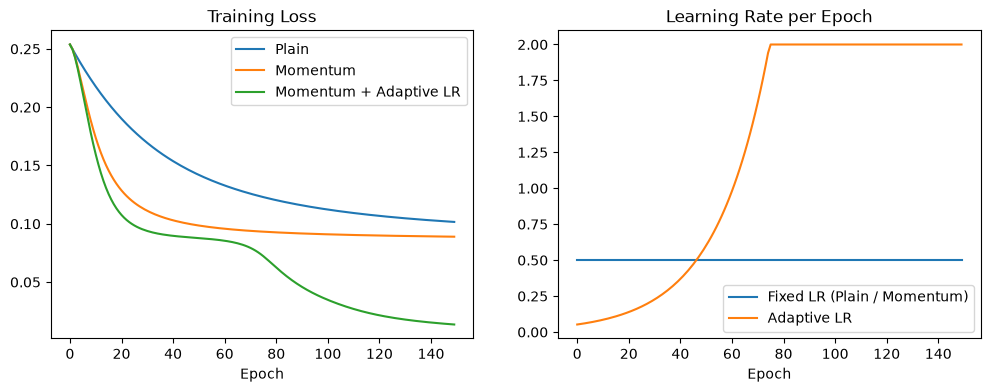

In [219]:
plt.figure(figsize=(12, 4))

plt.subplot(121)
plt.plot(loss1, label="Plain")
plt.plot(loss2, label="Momentum")
plt.plot(loss3, label="Momentum + Adaptive LR")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(122)
plt.plot([0.5] * 150, label="Fixed LR (Plain / Momentum)")
plt.plot(lrs, label="Adaptive LR")
plt.title("Learning Rate per Epoch")
plt.xlabel("Epoch")
plt.legend()

plt.show()

### RESULT:
Thus, the Python program for backpropagation with momentum and adaptive learning rate was executed successfully and the comparative performance was verified.

---
# Ex_8 Batch vs Incremental training

### AIM:
To implement and compare the learning dynamics, convergence rates, and loss trajectories of Batch Gradient Descent versus Incremental (Stochastic/Online) Gradient Descent on a binary classification dataset.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Scikit-Learn (load_iris, train_test_split, StandardScaler), Matplotlib, Jupyter Notebook

## Import necessary libraries

In [220]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Load dataset - use only 2 classes(binary classification)

In [221]:
iris = load_iris()
mask = iris.target != 2
X = StandardScaler().fit_transform(iris.data[mask])
y = iris.target[mask].reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr, epochs = 0.1, 30

## Batch training

In [222]:
Wb, bb, batch_mse = np.zeros((4, 2)), 0, []
for e in range(epochs):
    out = 1 / (1 + np.exp(-(np.dot(X_train, Wb) + bb)))
    err = y_train - out
    Wb += lr * X_train.T.dot(err) / len(X_train)
    bb += lr * np.sum(err) / len(X_train)
    batch_mse.append(np.mean(err**2))

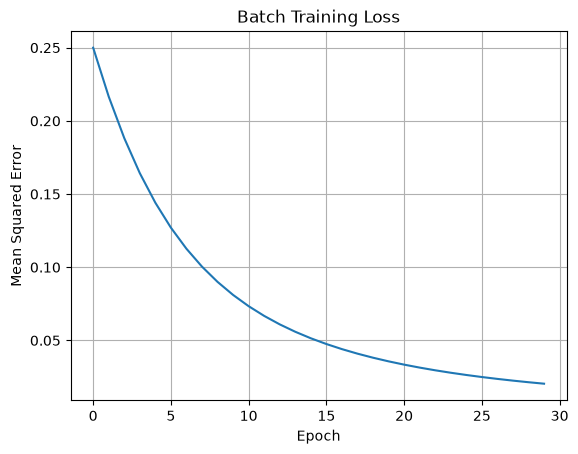

In [223]:
import matplotlib.pyplot as plt

plt.plot(batch_mse)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Batch Training Loss")
plt.grid()
plt.show()

In [224]:
Wi, bi, inc_mse = np.zeros((4, 1)), 0, []
for e in range(epochs):
    total_err = 0
    for i in range(len(X_train)):
        out = 1 / (1 + np.exp(-(np.dot(X_train[i], Wi) + bi)))
        err = y_train[i] - out
        Wi += lr * err * X_train[i].reshape(-1, 1)
        bi += lr * err
        total_err += err**2
    inc_mse.append(total_err / len(X_train))

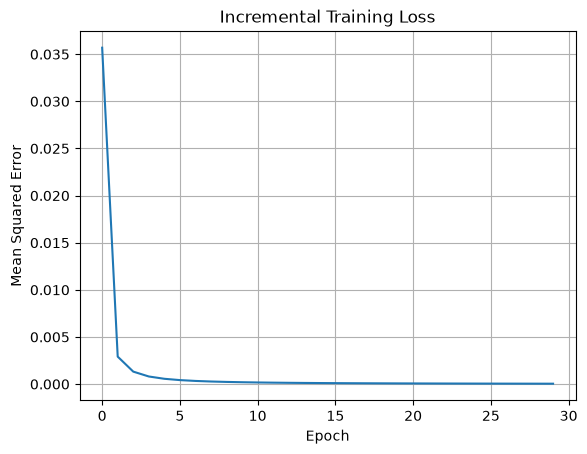

In [225]:
import matplotlib.pyplot as plt

plt.plot(inc_mse)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Incremental Training Loss")
plt.grid()
plt.show()

In [226]:
acc_b = np.mean((1 / (1 + np.exp(-(np.dot(X_test, Wb) + bb))) >= 0.5).astype(int) == y_test)
acc_i = np.mean((1 / (1 + np.exp(-(np.dot(X_test, Wi) + bi))) >= 0.5).astype(int) == y_test)

print("Batch Final Mse:", batch_mse[-1], " | Accuracy: %.2f%%" % (acc_b * 100))
print("Incremental Final Mse:", inc_mse[-1][0], " | Accuracy: %.2f%%" % (acc_i * 100))

Batch Final Mse: 0.020420089554083497  | Accuracy: 100.00%
Incremental Final Mse: 4.183018685312012e-05  | Accuracy: 100.00%


### RESULT:
Thus, the Python program comparing batch and incremental training was executed successfully and the training loss curves were verified.

---
# Ex_10 Hamming Network for Pattern Recognition

### AIM:
To implement a two-layer Hamming Neural Network consisting of a feedforward correlation matching layer and a recurrent MAXNET lateral inhibition subnetwork for bipolar pattern recognition.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Jupyter Notebook

## Import necessary libraries

In [227]:
import numpy as np

## Stored exemplar pattern

In [228]:
exemplars = np.array([
    [ 1, -1,  1, -1,  1, -1],
    [-1,  1, -1,  1, -1,  1],
    [ 1,  1,  1, -1, -1, -1]
])

In [229]:
exemplars

array([[ 1, -1,  1, -1,  1, -1],
       [-1,  1, -1,  1, -1,  1],
       [ 1,  1,  1, -1, -1, -1]])

In [230]:
test_input = np.array([1, -1, -1, -1, 1, -1])
n = exemplars.shape[1]
m = exemplars.shape[0]

In [231]:
test_input

array([ 1, -1, -1, -1,  1, -1])

In [232]:
n

6

In [233]:
weights = exemplars / 2
bias = n / 2
net_input = np.dot(weights, test_input) + bias
print("Net Input(similarity scores):", net_input)

Net Input(similarity scores): [5. 1. 3.]


In [234]:
weights

array([[ 0.5, -0.5,  0.5, -0.5,  0.5, -0.5],
       [-0.5,  0.5, -0.5,  0.5, -0.5,  0.5],
       [ 0.5,  0.5,  0.5, -0.5, -0.5, -0.5]])

In [235]:
activation = net_input.copy()
epsilon = 1 / m
iteration = 0
while np.count_nonzero(activation > 0) > 1:
    iteration += 1
    new_activation = activation - epsilon * (np.sum(activation[activation > 0]) - activation)
    new_activation = np.maximum(new_activation, 0)
    activation = new_activation
    print(f"Iteration {iteration}:{activation}")

Iteration 1:[3.66666667 0.         1.        ]
Iteration 2:[3.33333333 0.         0.        ]


In [236]:
winner_index = np.argmax(activation)
print("\ntext input:", test_input)
print("Best matching patterns index:", winner_index)
print("Best matching patterns:", exemplars[winner_index])
hamming_distance = np.sum(test_input != exemplars[winner_index])
print("hamming distance from winner:", hamming_distance)


text input: [ 1 -1 -1 -1  1 -1]
Best matching patterns index: 0
Best matching patterns: [ 1 -1  1 -1  1 -1]
hamming distance from winner: 1


### RESULT:
Thus, the Python program for the Hamming Network for pattern recognition was executed successfully and the exemplar matching via MAXNET was verified.

---
# Ex_11 Self organizing Map

### AIM:
To implement an unsupervised Kohonen Self-Organizing Map (SOM) using the MiniSom library to cluster and visualize the 4-dimensional Iris dataset in 2D space.

### SOFTWARE / LIBRARIES REQUIRED:
Python 3.x, NumPy, Scikit-Learn (load_iris, MinMaxScaler), MiniSom, Matplotlib, Jupyter Notebook

## Import necessary libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

In [3]:
iris = load_iris()
X = iris.data
y = iris.target
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [4]:
X = MinMaxScaler().fit_transform(X)
X

array([[0.22222222, 0.625     , 0.06779661, 0.04166667],
       [0.16666667, 0.41666667, 0.06779661, 0.04166667],
       [0.11111111, 0.5       , 0.05084746, 0.04166667],
       [0.08333333, 0.45833333, 0.08474576, 0.04166667],
       [0.19444444, 0.66666667, 0.06779661, 0.04166667],
       [0.30555556, 0.79166667, 0.11864407, 0.125     ],
       [0.08333333, 0.58333333, 0.06779661, 0.08333333],
       [0.19444444, 0.58333333, 0.08474576, 0.04166667],
       [0.02777778, 0.375     , 0.06779661, 0.04166667],
       [0.16666667, 0.45833333, 0.08474576, 0.        ],
       [0.30555556, 0.70833333, 0.08474576, 0.04166667],
       [0.13888889, 0.58333333, 0.10169492, 0.04166667],
       [0.13888889, 0.41666667, 0.06779661, 0.        ],
       [0.        , 0.41666667, 0.01694915, 0.        ],
       [0.41666667, 0.83333333, 0.03389831, 0.04166667],
       [0.38888889, 1.        , 0.08474576, 0.125     ],
       [0.30555556, 0.79166667, 0.05084746, 0.125     ],
       [0.22222222, 0.625     ,

## SOM

In [5]:
som = MiniSom(7, 7, 4, sigma=1.0, learning_rate=0.5)
som.random_weights_init(X)
som.train_random(X, 1000)

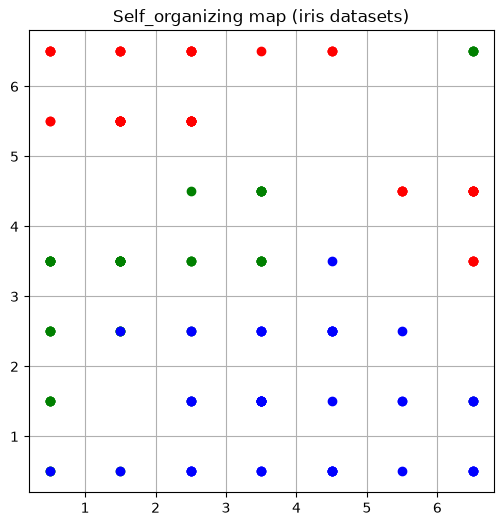

In [6]:
plt.figure(figsize=(6, 6))
for i, x in enumerate(X):
    w = som.winner(x)
    plt.scatter(w[0] + 0.5, w[1] + 0.5,
                c=['r', 'g', 'b'][y[i]],
                marker='o')

plt.title("Self_organizing map (iris datasets)")
plt.grid()
plt.show()

### RESULT:
Thus, the Python program for the Self-Organizing Map (SOM) was executed successfully and the 2D topological mapping of clusters was verified.